<a href="https://colab.research.google.com/github/JasonWachira/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nairobi to Kisumu: uniform cost search on a directed graph

This notebook:
1. Defines the road network as a weighted directed graph.
2. Runs **uniform cost search (UCS)** from Nairobi to Kisumu.


## 1. Graph definition
Adjacency list: `node -> {neighbor: edge_cost}`.

In [2]:
graph = {
    "Nairobi":   {"Thika": 45, "Naivasha": 90, "Narok": 142},
    "Thika":     {"Murang'a": 40},
    "Murang'a":  {"Nyeri": 65},
    "Nyeri":     {"Nyahururu": 98},
    "Nyahururu": {"Nakuru": 67},
    "Naivasha":  {"Nakuru": 70},
    "Nakuru":    {"Kericho": 104, "Eldoret": 156},
    "Narok":     {"Bomet": 87},
    "Bomet":     {"Kericho": 52, "Kisii": 80},
    "Eldoret":   {"Kakamega": 105},
    "Kericho":   {"Kisumu": 83},
    "Kakamega":  {"Kisumu": 52},
    "Kisii":     {"Kisumu": 110},
    "Kisumu":    {},
}

for src, edges in graph.items():
    for dst, w in edges.items():
        print(f"{src} -> {dst} ({w})")

Nairobi -> Thika (45)
Nairobi -> Naivasha (90)
Nairobi -> Narok (142)
Thika -> Murang'a (40)
Murang'a -> Nyeri (65)
Nyeri -> Nyahururu (98)
Nyahururu -> Nakuru (67)
Naivasha -> Nakuru (70)
Nakuru -> Kericho (104)
Nakuru -> Eldoret (156)
Narok -> Bomet (87)
Bomet -> Kericho (52)
Bomet -> Kisii (80)
Eldoret -> Kakamega (105)
Kericho -> Kisumu (83)
Kakamega -> Kisumu (52)
Kisii -> Kisumu (110)


## 2. Uniform cost search



In [3]:
import heapq

def uniform_cost_search(graph, start, goal):
    frontier = [(0, start)]          # priority queue of (path_cost, node)
    best_cost = {start: 0}           # cheapest known cost to each node
    parent = {start: None}           # for path reconstruction
    explored = set()
    order = []

    while frontier:
        cost, node = heapq.heappop(frontier)

        if node in explored:         # stale queue entry, skip it
            continue

        if node == goal:             # goal test on POP
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            return cost, path[::-1], order

        explored.add(node)
        order.append((node, cost))

        for neighbor, weight in graph[node].items():
            new_cost = cost + weight
            if neighbor not in explored and new_cost < best_cost.get(neighbor, float("inf")):
                best_cost[neighbor] = new_cost
                parent[neighbor] = node
                heapq.heappush(frontier, (new_cost, neighbor))
    # if no path is viable
    return float("inf"), [], order

## 3. Run it

In [4]:
cost, path, order = uniform_cost_search(graph, "Nairobi", "Kisumu")

print("Expansion order:")
for node, g in order:
    print(f"  {node:<10} g = {g}")

print(f"\nPath: {' -> '.join(path)}")
print(f"Total cost: {cost}")

Expansion order:
  Nairobi    g = 0
  Thika      g = 45
  Murang'a   g = 85
  Naivasha   g = 90
  Narok      g = 142
  Nyeri      g = 150
  Nakuru     g = 160
  Bomet      g = 229
  Nyahururu  g = 248
  Kericho    g = 264
  Kisii      g = 309
  Eldoret    g = 316

Path: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost: 347


## 4. Try other routes

Change `start` and `goal` to search between any two towns.

In [5]:
def show_route(start, goal):
    c, p, _ = uniform_cost_search(graph, start, goal)
    if not p:
        print(f"No route from {start} to {goal}")
    else:
        print(f"{start} -> {goal}: {' -> '.join(p)} (cost {c})")

show_route("Nairobi", "Kisumu")
show_route("Nairobi", "Eldoret")
show_route("Narok", "Kisumu")
show_route("Kisumu", "Nairobi")   # directed graph: no way back

Nairobi -> Kisumu: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu (cost 347)
Nairobi -> Eldoret: Nairobi -> Naivasha -> Nakuru -> Eldoret (cost 316)
Narok -> Kisumu: Narok -> Bomet -> Kericho -> Kisumu (cost 222)
No route from Kisumu to Nairobi


## 5. Team Photo
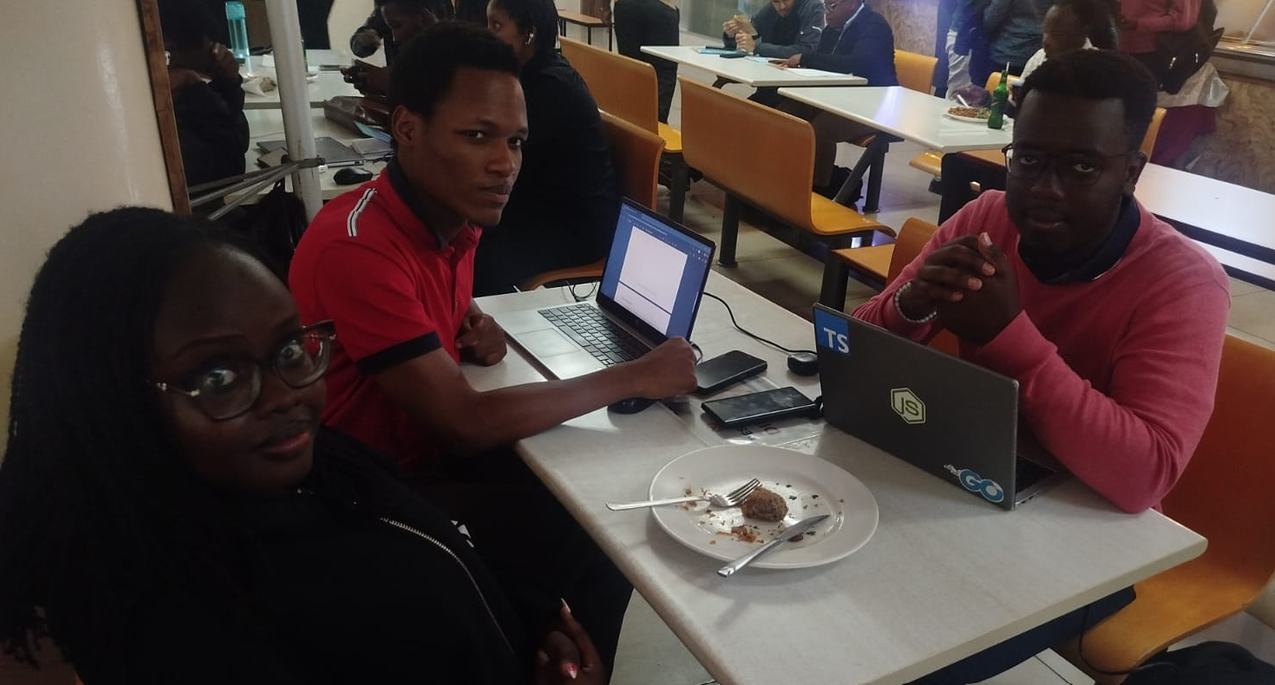